# Renda familiar e tipo de escola explicam quanto da nota do ENEM?

Base: microdados do ENEM 2023 (INEP). Entram os participantes presentes nas quatro provas, com redação válida e renda familiar informada (questão Q006), num total de 2,57 milhões de pessoas.

A medida de nota é a média simples das quatro provas objetivas e da redação.

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect("../dados/enem.duckdb", read_only=True)
con.sql("select * from resumo").df()

,participantes,escola_nao_informada,nota_media_geral,r2_renda_linear,correlacao_renda
0,2569190,1566349,548.8,0.213,0.462


## 1. A nota sobe a cada faixa de renda, sem exceção

Da faixa "nenhuma renda" até "acima de R$ 26.400" a média sobe cerca de 158 pontos, e a distância cresce em todas as 17 faixas. Matemática é a prova mais sensível à renda, e a redação mostra a maior diferença absoluta.

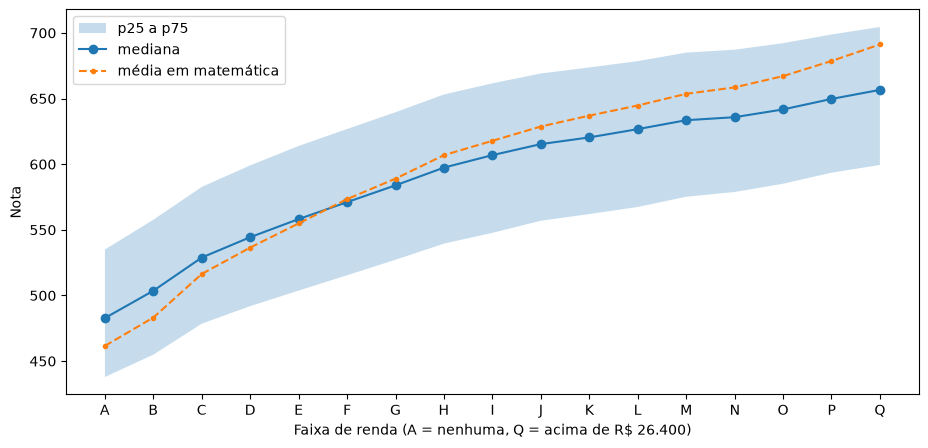

,faixa_renda,descricao,participantes,nota_media,matematica,redacao
0,A,Nenhuma renda,144154,490.3,461.6,568.5
1,B,Até R$ 1.320,733318,508.9,483.2,600.1
2,C,R$ 1.320 a 1.980,397170,532.4,516.4,623.6
3,D,R$ 1.980 a 2.640,285154,546.9,536.5,642.6
4,E,R$ 2.640 a 3.300,203099,559.8,554.9,661.4
5,F,R$ 3.300 a 3.960,123646,571.5,573.4,677.5
6,G,R$ 3.960 a 5.280,196822,583.1,589.0,695.3
7,H,R$ 5.280 a 6.600,108022,595.3,606.9,713.2
8,I,R$ 6.600 a 7.920,68088,603.4,617.8,726.2
9,J,R$ 7.920 a 9.240,60542,611.1,628.7,737.0


In [2]:
renda = con.sql("select * from nota_por_renda").df()
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(renda.faixa_renda, renda.p25, renda.p75, alpha=0.25, label="p25 a p75")
ax.plot(renda.faixa_renda, renda.mediana, marker="o", label="mediana")
ax.plot(renda.faixa_renda, renda.matematica, marker=".", linestyle="--", label="média em matemática")
ax.set_xlabel("Faixa de renda (A = nenhuma, Q = acima de R$ 26.400)")
ax.set_ylabel("Nota")
ax.legend()
plt.show()
renda[["faixa_renda", "descricao", "participantes", "nota_media", "matematica", "redacao"]]

## 2. Na mesma faixa de renda, a escola privada fica de 43 a 84 pontos à frente

Comparar escola pública com privada sem controlar a renda mistura os dois efeitos. Mesmo dentro de cada faixa de renda a diferença continua grande, e ela é maior justamente nos extremos: 84 pontos entre quem declara não ter renda e 66 na faixa mais rica. Um aluno de escola privada com renda de até R$ 1.320 tem média parecida com a de um aluno de escola pública com renda entre R$ 5.280 e R$ 7.920.

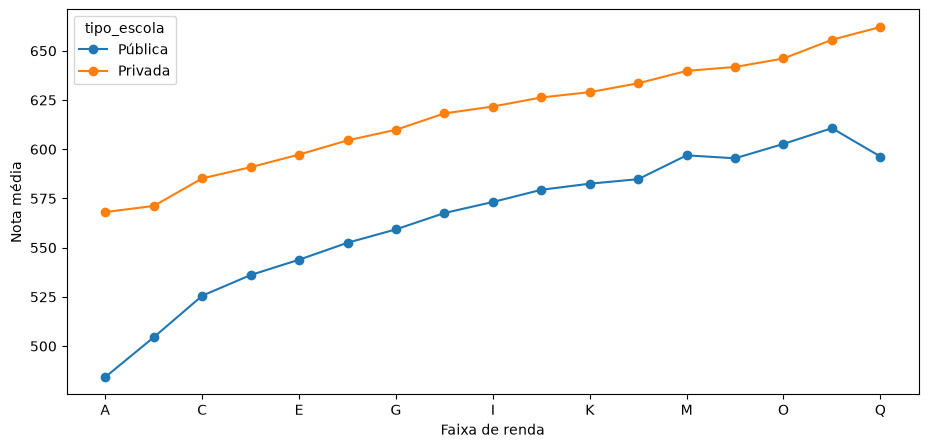

tipo_escola,Privada,Pública,diferenca
faixa_renda,,,
A,568.1,484.3,83.8
B,571.2,504.5,66.7
C,585.2,525.6,59.6
D,590.9,536.1,54.8
E,597.3,543.9,53.4
F,604.5,552.5,52.0
G,609.9,559.3,50.6
H,618.2,567.6,50.6
I,621.7,573.2,48.5


In [3]:
escola = con.sql("select * from nota_por_renda_escola").df()
tabela = escola.pivot(index="faixa_renda", columns="tipo_escola", values="nota_media")
tabela["diferenca"] = tabela["Privada"] - tabela["Pública"]
tabela.plot(y=["Pública", "Privada"], marker="o", figsize=(11, 5), ylabel="Nota média", xlabel="Faixa de renda")
plt.show()
tabela

## 3. Quanto da variação das notas os dois fatores explicam

A medida é a fração da variância das notas que fica entre os grupos (eta²). Ela foi calculada só para os participantes que informaram o tipo de escola, cerca de 1 milhão de pessoas, que em geral estavam concluindo o ensino médio em 2023. Quem não respondeu é, na maioria, quem já tinha terminado o ensino médio.

In [4]:
con.sql("select * from variancia_explicada").df()

,fator,pct_variancia_explicada
0,Tipo de escola,19.4
1,Renda familiar,23.5
2,Renda + escola,28.0


**Conclusão:** renda e tipo de escola juntos explicam cerca de **28%** da variação das notas. É muito para dois fatores, mas deixa de fora mais de 70%. Os dois fatores se sobrepõem bastante: sozinhos, a renda explica 23,5% e a escola 19,4%, e juntos chegam a apenas 28%. Isso acontece porque quem estuda em escola privada costuma ter renda maior.

## 4. Desigualdade entre estados

O ranking usa window functions (`rank() over`). A distância entre escola privada e pública passa de 100 pontos em oito estados: PI, CE, TO, AC, MA, AM, MT e GO.

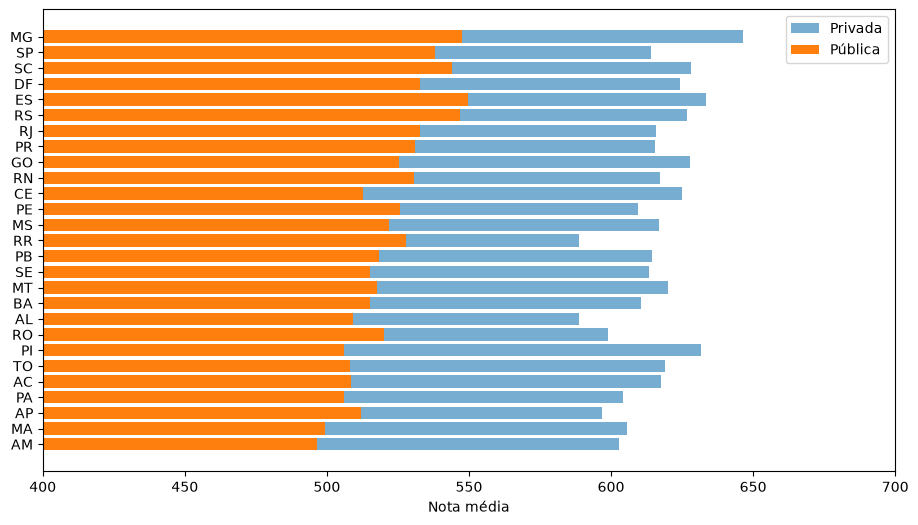

,posicao,uf,participantes,nota_media,media_publica,media_privada,diferenca_privada_publica,posicao_publica,desvio_da_media_nacional
0,1,MG,242860,571.3,547.4,646.5,99.1,2,29.5
1,2,SP,399207,570.1,538.1,614.1,76.0,5,28.3
2,3,SC,60360,567.5,544.0,628.3,84.3,4,25.8
3,4,DF,48592,566.0,532.8,624.1,91.4,7,24.3
4,5,ES,47353,564.3,549.7,633.4,83.7,1,22.6
5,6,RS,107325,563.8,546.7,626.6,79.9,3,22.0
6,7,RJ,177828,563.7,532.9,615.7,82.8,6,21.9
7,8,PR,111233,556.4,531.0,615.4,84.4,8,14.7
8,9,GO,92757,550.6,525.5,627.9,102.4,12,8.8
9,10,RN,70072,544.2,530.8,617.3,86.5,9,2.5


In [5]:
uf = con.sql("select * from ranking_uf").df()
fig, ax = plt.subplots(figsize=(11, 6))
uf_ordenado = uf.sort_values("nota_media")
ax.barh(uf_ordenado.uf, uf_ordenado.media_privada, label="Privada", alpha=0.6)
ax.barh(uf_ordenado.uf, uf_ordenado.media_publica, label="Pública")
ax.set_xlim(400, 700)
ax.set_xlabel("Nota média")
ax.legend()
plt.show()
uf

## Limitações

- A renda é declarada pelo participante e vem agrupada em faixas.
- Cerca de 60% dos presentes não informaram o tipo de escola, por isso a análise de escola vale para quem estava terminando o ensino médio.
- Os resultados mostram correlação, não causalidade.